### project objective
- Barclays Bank Facing high customer churn rate , and customer not keep using services, being an data scientist your task is to indentify the companies problem so that they can get real time insight and managementand can take decision accordingly, Previously banks were not getting timely insights and did not take decision timely, that cost high customer churn rate , previous methodology were old and not upto dated, presently bank need live analysis and corrective measures to predict the future churn rates and live analysis.

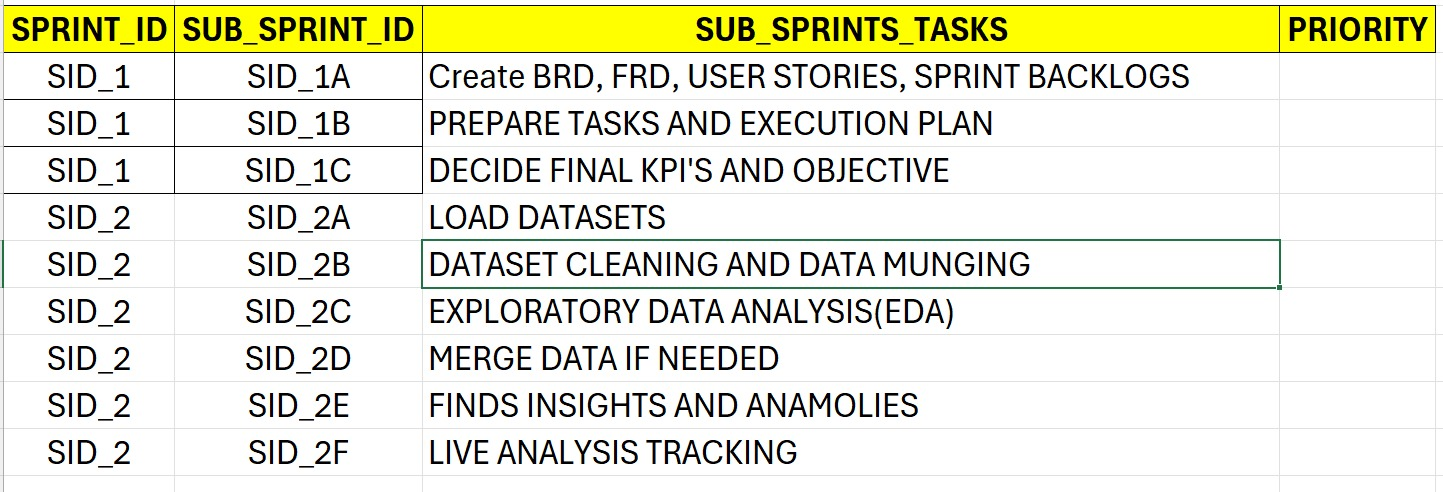

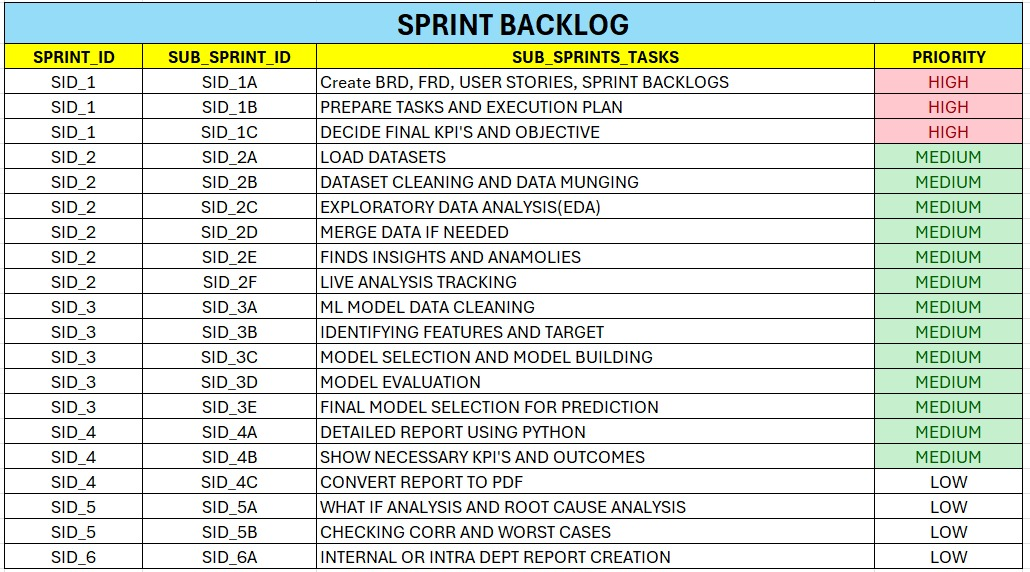

# Step 1 load important modules

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns # to create visuals
import os # to rename or remove any file
import time
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import accuracy_score
from sklearn.metrics import recall_score
import pickle # to dump ml model
import IPython as IP # to display image, pdf
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier
import warnings
warnings.filterwarnings('ignore')
print("All models loaded sucessfully")




All models loaded sucessfully


Step 2: load dataset

In [3]:
url = "https://github.com/amankr0804/BARCLAYS-CUSTOMER-CHURN-ANALYSIS/raw/refs/heads/master/Datasets/ActiveCustomer.xlsx"
active_customer_df = pd.read_excel(url)
print("done")

done


In [4]:
url = "https://github.com/amankr0804/BARCLAYS-CUSTOMER-CHURN-ANALYSIS/raw/refs/heads/master/Datasets/CreditCard.xlsx"
credit_card_df = pd.read_excel(url)
print("done")

done


In [5]:
url = "https://github.com/amankr0804/BARCLAYS-CUSTOMER-CHURN-ANALYSIS/raw/refs/heads/master/Datasets/ExitCustomer.xlsx"
exit_customer_df = pd.read_excel(url)
print("done")

done


In [6]:
url = "https://github.com/amankr0804/BARCLAYS-CUSTOMER-CHURN-ANALYSIS/raw/refs/heads/master/Datasets/Gender.xlsx"
gender_df  = pd.read_excel(url)
print("done")


done


In [7]:
url = "https://github.com/amankr0804/BARCLAYS-CUSTOMER-CHURN-ANALYSIS/raw/refs/heads/master/Datasets/Geography.xlsx"
geography_df = pd.read_excel(url)
print("done")


done


In [8]:
url = "https://github.com/amankr0804/BARCLAYS-CUSTOMER-CHURN-ANALYSIS/raw/refs/heads/master/Datasets/Bank_Churn.csv"
bank_churn_df = pd.read_csv(url)
print("done")

done


In [9]:
url = "https://github.com/amankr0804/BARCLAYS-CUSTOMER-CHURN-ANALYSIS/raw/refs/heads/master/Datasets/CustomerInfo.csv"
customer_info_df = pd.read_csv(url)
print("done")

done


In [13]:
all_dfs=[active_customer_df,
         credit_card_df,
         exit_customer_df,
         gender_df,
         geography_df,
         bank_churn_df,
         customer_info_df]
for i in all_dfs:
  print('='*50)
  display(i.sample(2))


,ActiveID,ActiveCategory
1,0,Inactive Member
0,1,Active Member


,CreditID,Category
1,0,non credit card holder
0,1,credit card holder


,ExitID,ExitCategory
1,0,Retain
0,1,Exit


,GenderID,GenderCategory
1,2,Female
0,1,Male


,GeographyID,GeographyLocation
0,1,France
1,2,Spain


,RowNumber,CustomerId,CreditScore,GeographyID,GenderID,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Bank DOJ
7541,7542,15649430,723,1,1,28,7,0.0,2,1,1,123885.88,0,12-09-2016
2333,2334,15635972,484,2,1,36,4,0.0,2,1,0,186136.48,0,27-10-2018


,CustomerId,Surname
5005,15741032,Tsao
3431,15688193,Graham


STEP 3: EDA(Exploratory data analysis)

In [14]:
#step 3.1 sow bank_churn_df sample
bank_churn_df.sample(5)

,RowNumber,CustomerId,CreditScore,GeographyID,GenderID,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Bank DOJ
2649,2650,15612615,616,1,2,37,5,0.00,2,1,0,86242.18,0,14-04-2018
3554,3555,15662865,658,2,1,36,6,0.00,2,0,1,84927.42,0,12-03-2017
8723,8724,15803202,350,1,1,51,5,0.00,1,1,1,125823.79,1,13-07-2018
8410,8411,15609913,743,1,2,46,5,0.00,1,1,0,113436.08,0,01-04-2018
1033,1034,15695475,645,1,1,29,3,130131.08,2,0,1,196474.35,0,05-12-2019


In [15]:
#step 3.2 show df shape size
bank_churn_df.shape
#14 columns and 10k rows

(10000, 14)

In [16]:
bank_churn_df.size

140000

In [17]:
# step 3.3 combine all dfs
merged_df = pd.merge(bank_churn_df, customer_info_df, on = 'CustomerId')
merged_df = pd.merge(merged_df, geography_df, on = 'GeographyID')
final_df = pd.merge(merged_df, gender_df, on = 'GenderID')
final_df

,RowNumber,CustomerId,CreditScore,GeographyID,GenderID,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Bank DOJ,Surname,GeographyLocation,GenderCategory
0,1,15634602,619,1,2,42,7,0.00,1,1,1,101348.88,1,23-03-2016,Hargrave,France,Female
1,2,15647311,608,2,2,41,4,83807.86,1,0,1,112542.58,0,09-10-2018,Hill,Spain,Female
2,3,15619304,502,1,2,42,4,159660.80,3,1,0,113931.57,1,25-03-2019,Onio,France,Female
3,4,15701354,699,1,2,39,3,0.00,2,0,0,93826.63,0,24-10-2019,Boni,France,Female
4,5,15737888,850,2,2,43,3,125510.82,1,1,1,79084.10,0,22-11-2019,Mitchell,Spain,Female
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,771,1,1,39,5,0.00,2,1,0,96270.64,0,25-03-2018,Obijiaku,France,Male
9996,9997,15569892,516,1,1,35,5,57369.61,1,1,1,101699.77,0,17-06-2018,Johnstone,France,Male
9997,9998,15584532,709,1,2,36,5,0.00,1,0,1,42085.58,1,18-03-2018,Liu,France,Female
9998,9999,15682355,772,3,1,42,3,75075.31,2,1,0,92888.52,1,12-11-2019,Sabbatini,Germany,Male


In [18]:
final_df.shape

(10000, 17)

In [19]:
#step 3.4 show column info
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   RowNumber          10000 non-null  int64  
 1   CustomerId         10000 non-null  int64  
 2   CreditScore        10000 non-null  int64  
 3   GeographyID        10000 non-null  int64  
 4   GenderID           10000 non-null  int64  
 5   Age                10000 non-null  int64  
 6   Tenure             10000 non-null  int64  
 7   Balance            10000 non-null  float64
 8   NumOfProducts      10000 non-null  int64  
 9   HasCrCard          10000 non-null  int64  
 10  IsActiveMember     10000 non-null  int64  
 11  EstimatedSalary    10000 non-null  float64
 12  Exited             10000 non-null  int64  
 13  Bank DOJ           10000 non-null  object 
 14  Surname            10000 non-null  object 
 15  GeographyLocation  10000 non-null  object 
 16  GenderCategory     1000

In [20]:
#step 3.5 drop nan or missing values
final_df.dropna(inplace=True)
print("Done")

Done


In [21]:
#step 3.6 show data stats
final_df.describe(include = 'number')

,RowNumber,CustomerId,CreditScore,GeographyID,GenderID,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,1.749500,1.454300,38.921800,4.86430,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,0.830433,0.497932,10.487806,1.21525,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,1.000000,1.000000,18.000000,3.00000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,1.000000,1.000000,32.000000,4.00000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,1.000000,1.000000,37.000000,5.00000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,3.000000,2.000000,44.000000,6.00000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,3.000000,2.000000,92.000000,7.00000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [22]:
#step 3.7 show categorical data stats
final_df.describe(include = 'object')

,Bank DOJ,Surname,GeographyLocation,GenderCategory
count,10000,10000,10000,10000
unique,1332,2932,3,2
top,16-12-2017,Smith,France,Male
freq,35,32,5014,5457


In [23]:
#step 3.8 show data correlation
corr = final_df.corr(numeric_only = True)
corr
# corr ranges from -1 to +1
#-1 for highly negative and +1 for highly positive , 0 for no corr

,RowNumber,CustomerId,CreditScore,GeographyID,GenderID,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
RowNumber,1.000000,0.004202,0.005840,-0.005196,-0.018196,0.000783,0.002901,-0.009067,0.007246,0.000599,0.012044,-0.005988,-0.016571
CustomerId,0.004202,1.000000,0.005308,0.000821,0.002641,0.009497,0.003884,-0.012419,0.016972,-0.014025,0.001665,0.015271,-0.006248
CreditScore,0.005840,0.005308,1.000000,0.008267,0.002857,-0.003965,-0.007355,0.006268,0.012238,-0.005458,0.025651,-0.001384,-0.027094
GeographyID,-0.005196,0.000821,0.008267,1.000000,0.016936,0.048092,-0.003858,0.348700,-0.006180,0.004036,-0.012692,0.007382,0.153771
GenderID,-0.018196,0.002641,0.002857,0.016936,1.000000,0.027544,-0.008018,-0.012087,0.021859,-0.005766,-0.022544,0.008112,0.106512
Age,0.000783,0.009497,-0.003965,0.048092,0.027544,1.000000,0.010788,0.028308,-0.030680,-0.011721,0.085472,-0.007201,0.285323
Tenure,0.002901,0.003884,-0.007355,-0.003858,-0.008018,0.010788,1.000000,0.001457,-0.029927,0.003857,-0.007576,0.005744,0.000699
Balance,-0.009067,-0.012419,0.006268,0.348700,-0.012087,0.028308,0.001457,1.000000,-0.304180,-0.014858,-0.010084,0.012797,0.118533
NumOfProducts,0.007246,0.016972,0.012238,-0.006180,0.021859,-0.030680,-0.029927,-0.304180,1.000000,0.003183,0.009612,0.014204,-0.047820
HasCrCard,0.000599,-0.014025,-0.005458,0.004036,-0.005766,-0.011721,0.003857,-0.014858,0.003183,1.000000,-0.011866,-0.009933,-0.007138


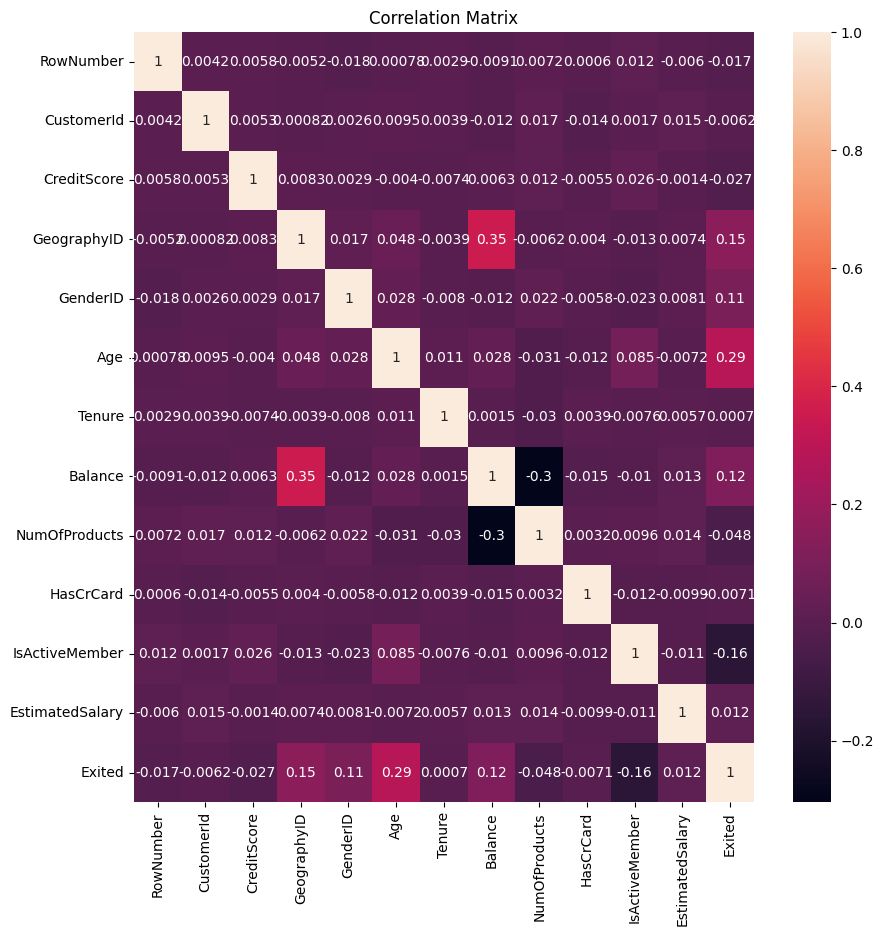

In [24]:
#step 3.9 plot
plt.figure(figsize = (10,10))
plt.title("Correlation Matrix")
sns.heatmap(corr, annot = True)
plt.show()

In [30]:
#step 3.10 divide column into req objects
textual_columns = final_df.select_dtypes('object').columns
numerical_columns = final_df.select_dtypes('number').columns
print("textual columns: \n" , textual_columns)
print('='*100)
print("numerical columns: \n" , numerical_columns)

textual columns: 
 Index(['Surname', 'GeographyLocation', 'GenderCategory'], dtype='object')
numerical columns: 
 Index(['CustomerId', 'CreditScore', 'GeographyID', 'GenderID', 'Age', 'Tenure',
       'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember',
       'EstimatedSalary', 'Exited'],
      dtype='object')


In [26]:
#step 3.11 change bank doj to datetime dtype
final_df['Bank DOJ'] = pd.to_datetime(final_df['Bank DOJ'])
print("done")

done


In [27]:
#step 3.12 drop unwanted columns
final_df.drop('RowNumber', axis = 1, inplace = True)
#axis = 1 means drop column, axis = 0 means drop row
#inplace true means apply changes in original dataset
print("done")


done


In [28]:
final_df.columns

Index(['CustomerId', 'CreditScore', 'GeographyID', 'GenderID', 'Age', 'Tenure',
       'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember',
       'EstimatedSalary', 'Exited', 'Bank DOJ', 'Surname', 'GeographyLocation',
       'GenderCategory'],
      dtype='object')

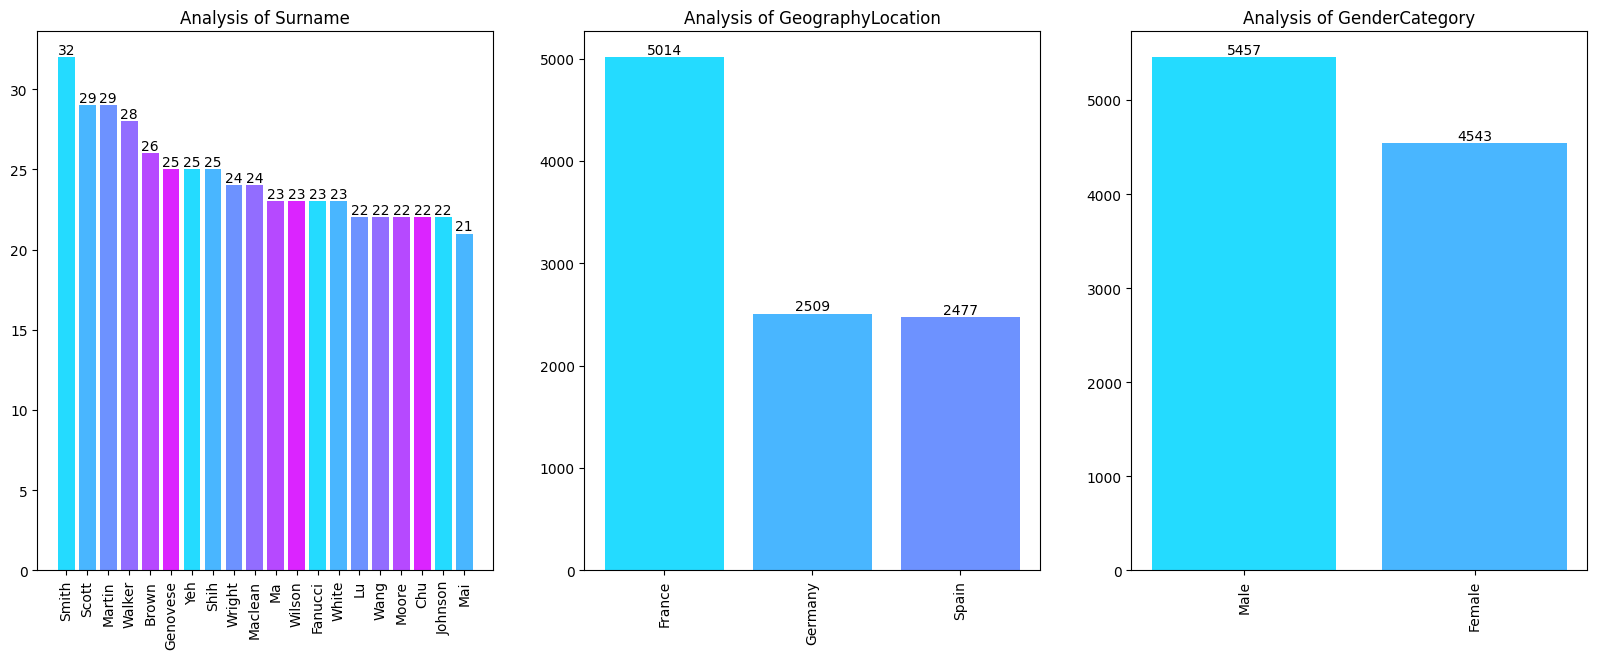

In [31]:
#step 3.13 univariated analysis
#means single columns analysis
plt.figure(figsize = (20,7))
for i , j in enumerate(textual_columns):
  plt.subplot(1,3,i+1)
  temp_df = final_df[j].value_counts().head(20)
  x = temp_df.index
  y = temp_df.values
  plt.title(f"Analysis of {j}")
  ax = plt.bar(x,y, color = sns.color_palette('cool'))
  plt.bar_label(ax)
  plt.xticks(rotation = 90)
plt.show()
 #pltshow() out of loop hai, subplot plots multiple plots at once
 #i is index and j is column name
 #enumerate means to get index and value at same time
 #value counts: to grouped data and counts its frequency
 #sns.color_palette to change color shades




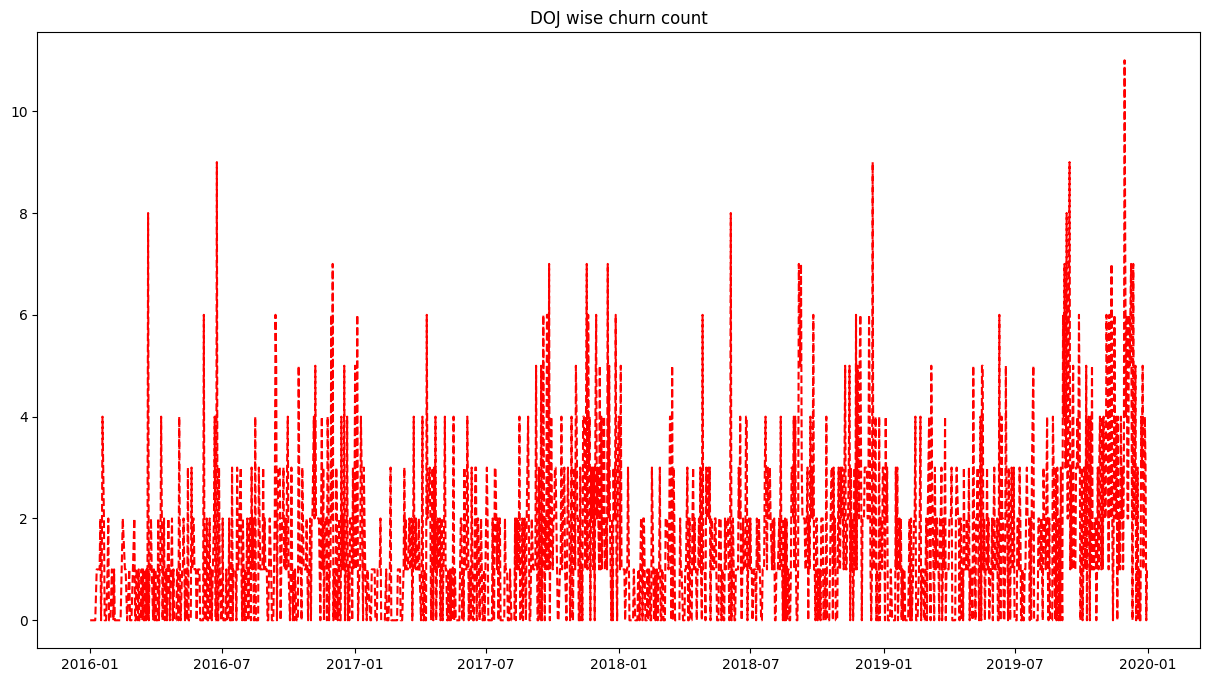

In [32]:
#step 3.14 bivariate analysis
#show bank DOJ wise churn count
plt.figure(figsize = (15,8))
plt.title("DOJ wise churn count")
temp_df = final_df.groupby('Bank DOJ')['Exited'].sum()
x = temp_df.index
y = temp_df.values
plt.plot(x,y, color = 'r', linestyle = '--')
plt.show()

In [33]:
#step 3.15 create new column for monthly and weekly analysis
final_df['Month'] = final_df['Bank DOJ'].dt.month_name()
final_df['Day'] = final_df['Bank DOJ'].dt.day_name()
#.dt. means datetime
final_df.sample()

,CustomerId,CreditScore,GeographyID,GenderID,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Bank DOJ,Surname,GeographyLocation,GenderCategory,Month,Day
7475,15599152,698,1,1,31,3,156111.24,1,0,0,134790.74,0,2019-10-06,Lai,France,Male,October,Sunday


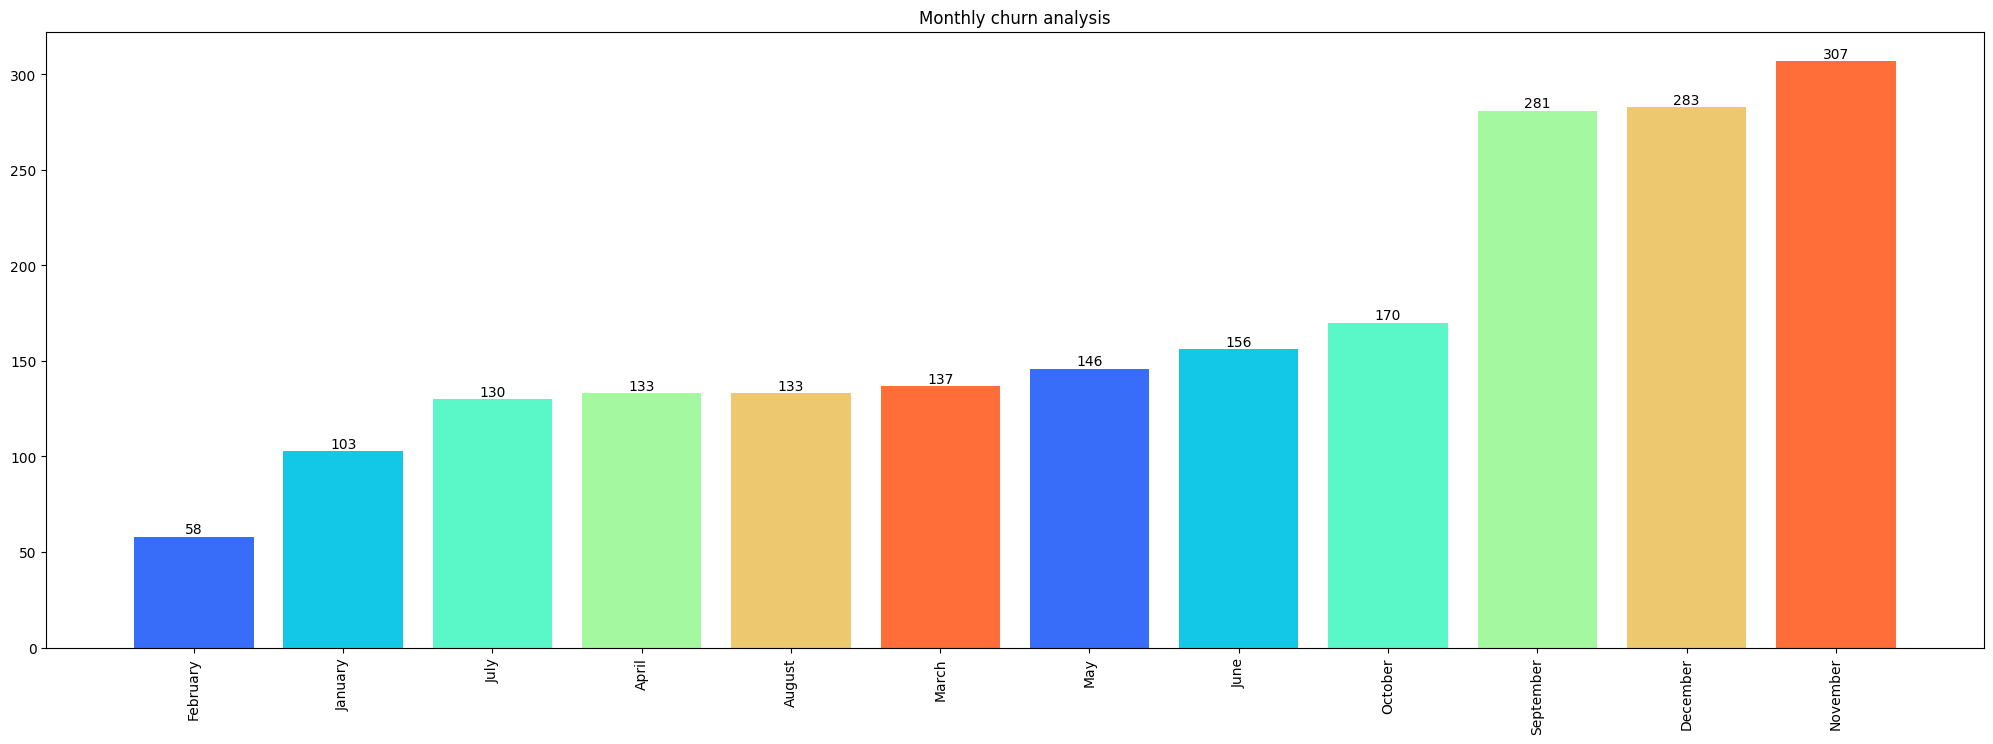

In [34]:
#step 3.16 show monthly churn analysis
plt.figure(figsize = (25,8))
plt.title("Monthly churn analysis")
temp_df = final_df.groupby('Month')['Exited'].sum().sort_values()
x = temp_df.index
y = temp_df.values
ax = plt.bar(x,y, color = sns.color_palette('rainbow'))
plt.bar_label(ax)
plt.xticks(rotation = 90)
plt.show()


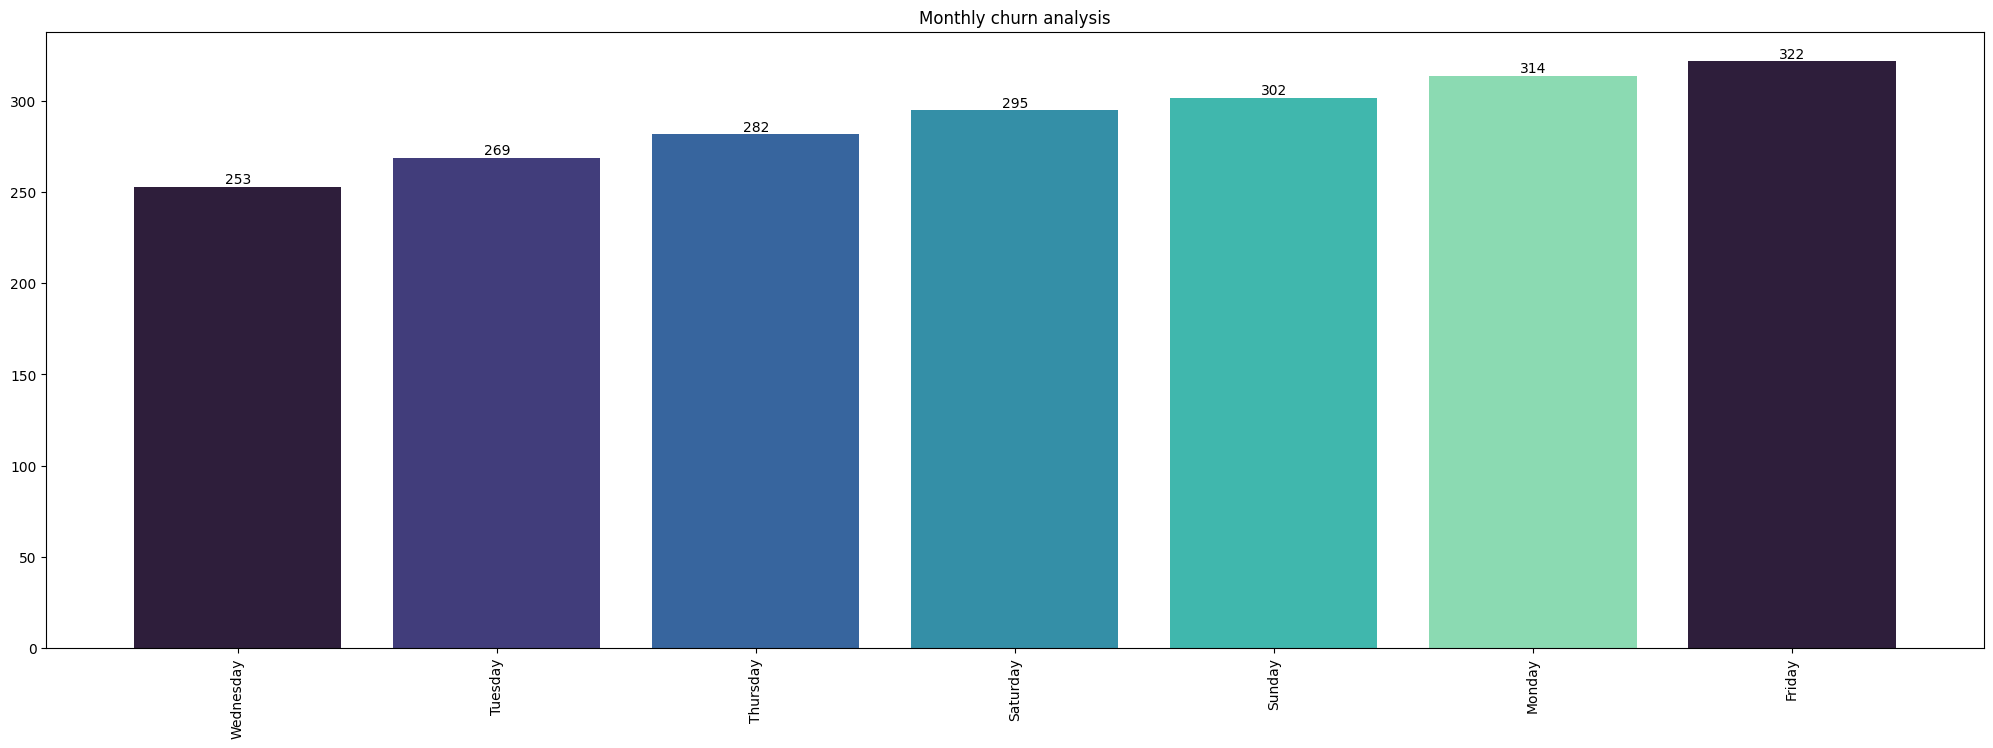

In [35]:
#step 3.17 show day churn analysis
plt.figure(figsize = (25,8))
plt.title("Monthly churn analysis")
temp_df = final_df.groupby('Day')['Exited'].sum().sort_values()
x = temp_df.index
y = temp_df.values
ax = plt.bar(x,y, color = sns.color_palette('mako'))
plt.bar_label(ax)
plt.xticks(rotation = 90)
plt.show()


In [36]:
#step 3.18 gender wise churn analyisi
#step 3.19 geography location wise analysis
#step 3.20 tenure wise analysis

In [37]:
final_df.sample()

,CustomerId,CreditScore,GeographyID,GenderID,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Bank DOJ,Surname,GeographyLocation,GenderCategory,Month,Day
9112,15567339,735,1,1,73,5,0.0,1,1,1,114283.33,0,2018-06-06,Shaw,France,Male,June,Wednesday


In [38]:
#step 3.21 removw unwanted cols for ml model
ml_drop_columns = ['CustomerId', 'GeographyID', 'GenderID', 'Bank DOJ', 'Surname', 'Day']
ml_df = final_df.drop(ml_drop_columns, axis = 1, inplace = False)
ml_df.sample()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,GeographyLocation,GenderCategory,Month
7845,648,34,5,0.0,1,1,1,167931.81,0,France,Male,September


#STEP 4: FEATURE EXTRACTION
 - ml only works with numerical data if we are getting any textual data we need to convert it to numeric data
 this tech is called feature engineering
 here geographylocation, gendercategory, or month is textual in nature

In [39]:
#Typed of techniques
#OHE(one hot encoding)
#map using dict
#apply lambda fn.
#categoral encoding
#get dummies
#ordianl encoding
#TF-DF
#BOW: bag of words
#advance: countvectorizer, word embeddings
#more advance : vector database using cosine technologies

In [40]:
#step 4.1 mapping
import calendar
months_name = list(calendar.month_name)[1:]
index = list(range(len(months_name)))
map = dict(zip(months_name, index))
ml_df['Month'] = ml_df['Month'].map(map)
ml_df.sample()
#zip: binds two objects together
#.map: method to map key with value
#run only once...second time me NaN return krega...kyunki tb wo test num me convert ho jayega

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,GeographyLocation,GenderCategory,Month
5162,608,31,4,79962.92,2,1,0,60901.72,0,France,Male,7


In [41]:
ml_df['GeographyLocation'].unique()

array(['France', 'Spain', 'Germany'], dtype=object)

In [42]:
ml_df['GenderCategory'] = ml_df['GenderCategory'].map({'Male': 0, 'Female':1})
ml_df['GeographyLocation'] = ml_df['GeographyLocation'].map({'France': 0, 'Spain' : 1, 'Germany' : 2 })
ml_df.sample()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,GeographyLocation,GenderCategory,Month
2009,729,46,4,117837.43,1,1,0,104016.61,1,2,0,8


In [43]:
#step 4.2 show target vs feature corr
ml_df.corr()['Exited'].sort_values(ascending = False)

,Exited
Exited,1.000000
Age,0.285323
GeographyLocation,0.153771
Balance,0.118533
GenderCategory,0.106512
EstimatedSalary,0.012097
Month,0.002312
Tenure,0.000699
HasCrCard,-0.007138
CreditScore,-0.027094


#STEP 5: DIVIDE DATA IN FEATURE VS TARGET

In [44]:
x = ml_df.drop('Exited', axis = 1)
y = ml_df['Exited']
#x must be capital in dataframe
#y must be small in series
print(x.shape)
print(y.shape)

(10000, 11)
(10000,)


#STEP 6: DIVIDE DATA INTO TRAIN AND TEST

In [45]:
x_train, x_test, y_train, y_test = train_test_split(x,y, random_state = 42, test_size = 0.2)
print("x_train-shape: ", x_train.shape)
print("x_test-shape: ", x_test.shape)
print("y_train-shape: ", y_train.shape)
print("y_test-shape: ", y_test.shape)

x_train-shape:  (8000, 11)
x_test-shape:  (2000, 11)
y_train-shape:  (8000,)
y_test-shape:  (2000,)


#STEP 7: TO BE C